In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [49]:
print(np.__version__)
print(pd.__version__)

2.5.1
3.0.3


In [39]:
def split_train_test(data, test_ratio):
        shuffled_indices = np.random.permutation(len(data))
        test_set_size = int(len(data) * test_ratio)
        test_indices = shuffled_indices[:test_set_size]
        train_indices = shuffled_indices[test_set_size:]
        return data.iloc[train_indices], data.iloc[test_indices]

In [20]:
def function_generate_data(x):
    return ((x**4) - (2*x))/3 

In [21]:
Data = np.random.randn(2,1999)

In [23]:
Data[1] = function_generate_data(Data[0])

In [29]:
isit = False 
for i in range(500): 
 isit = function_generate_data(Data[0,i]) == Data[1,i]

In [31]:
isit

np.True_

In [43]:
Train_X = Data[0]
Train_y = Data[1]

In [44]:
Train_X , Train_y

(array([-0.42994374,  0.69459923,  0.66154408, ...,  0.37764783,
         1.35118614, -0.8028971 ], shape=(1999,)),
 array([ 0.2980192 , -0.38547433, -0.3771863 , ..., -0.24498527,
         0.21027426,  0.67378659], shape=(1999,)))

In [50]:
def sigmoid(x):
    return (1)/(1+ np.exp(-x))

In [55]:
print(sigmoid(999))

1.0


In [56]:
def sigmoid_derivative(x):
    return x * (1 - x)

In [57]:
def Relu(x):
    return max(0,x)

In [62]:
def Relu_derivative(x):
    if(x>0.0):
        return 1.0 
    else :
        return 0.0
    # return (x > 0.0)? 1.0:0.0;

In [65]:
Relu_derivative(-888),Relu_derivative(888)

(0.0, 1.0)

In [87]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):
        self.weights_1 = np.random.randn(input_size, hidden_size)
        self.biases_1 = np.random.randn(1, hidden_size)
        self.weights_2 = np.random.randn(hidden_size, output_size)
        self.biases_2 = np.random.randn(1, output_size)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        return x * (1 - x)

    def forward(self, X):
        self.hidden_layer_input = np.dot(X, self.weights_1) + self.biases_1
        self.hidden_layer_output = self.sigmoid(self.hidden_layer_input)
        self.output_layer_input = np.dot(self.hidden_layer_output, self.weights_2) + self.biases_2
        self.output = self.sigmoid(self.output_layer_input)
        return self.output

    def backward(self, X, y, learning_rate):
        output_error = y - self.output
        output_delta = output_error * self.sigmoid_derivative(self.output)

        hidden_error = output_delta.dot(self.weights_2.T)
        hidden_delta = hidden_error * self.sigmoid_derivative(self.hidden_layer_output)

        self.weights_2 += self.hidden_layer_output.T.dot(output_delta) * learning_rate
        self.biases_2 += np.sum(output_delta, axis=0, keepdims=True) * learning_rate
        self.weights_1 += X.T.dot(hidden_delta) * learning_rate
        self.biases_1 += np.sum(hidden_delta, axis=0, keepdims=True) * learning_rate

    def train(self, X, y, epochs, learning_rate):
        X.reshape(-1,1)
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, learning_rate)
            if (epoch+1) % 100 == 0:
                print(f"Epoch {epoch+1}/{epochs}, Loss: {np.mean(np.square(y - output))}")


In [88]:
class ImprovedNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):

        self.weights_1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.biases_1 = np.zeros((1, hidden_size))

        self.weights_2 = np.random.randn(hidden_size, output_size) * np.sqrt(1.0 / hidden_size)
        self.biases_2 = np.zeros((1, output_size))

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def forward(self, X):
        self.hidden_input = np.dot(X, self.weights_1) + self.biases_1
        self.hidden_output = self.relu(self.hidden_input)
   
        self.output = np.dot(self.hidden_output, self.weights_2) + self.biases_2
        return self.output

    def backward(self, X, y, learning_rate):
        n_samples = X.shape[0]

        output_error = (self.output - y) / n_samples
        
        d_weights_2 = np.dot(self.hidden_output.T, output_error)
        d_biases_2 = np.sum(output_error, axis=0, keepdims=True)
        
        hidden_error = np.dot(output_error, self.weights_2.T) * self.relu_derivative(self.hidden_input)
        d_weights_1 = np.dot(X.T, hidden_error)
        d_biases_1 = np.sum(hidden_error, axis=0, keepdims=True)
        
        self.weights_2 -= learning_rate * d_weights_2
        self.biases_2 -= learning_rate * d_biases_2
        self.weights_1 -= learning_rate * d_weights_1
        self.biases_1 -= learning_rate * d_biases_1

    def train(self, X, y, epochs, learning_rate):
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, learning_rate)
            if (epoch + 1) % 100 == 0 or epoch == 0:
                loss = np.mean(np.square(y - output))
                print(f"Epoch {epoch+1}/{epochs}, Loss (MSE): {loss:.6f}")


In [89]:
class TwoHiddenLayerNN:
    def __init__(self, input_size, hidden1_size, hidden2_size, output_size):
        self.W1 = np.random.randn(input_size, hidden1_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden1_size))
        
        self.W2 = np.random.randn(hidden1_size, hidden2_size) * np.sqrt(2.0 / hidden1_size)
        self.b2 = np.zeros((1, hidden2_size))
        

        self.W3 = np.random.randn(hidden2_size, output_size) * np.sqrt(1.0 / hidden2_size)
        self.b3 = np.zeros((1, output_size))

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def forward(self, X):

        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.relu(self.z1)
        

        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.relu(self.z2)
        

        self.z3 = np.dot(self.a2, self.W3) + self.b3
        self.output = self.z3
        return self.output

    def backward(self, X, y, learning_rate):
        n_samples = X.shape[0]
        

        dz3 = (self.output - y) / n_samples
        dW3 = np.dot(self.a2.T, dz3)
        db3 = np.sum(dz3, axis=0, keepdims=True)
        

        dz2 = np.dot(dz3, self.W3.T) * self.relu_derivative(self.z2)
        dW2 = np.dot(self.a1.T, dz2)
        db2 = np.sum(dz2, axis=0, keepdims=True)
        

        dz1 = np.dot(dz2, self.W2.T) * self.relu_derivative(self.z1)
        dW1 = np.dot(X.T, dz1)
        db1 = np.sum(dz1, axis=0, keepdims=True)
        

        self.W3 -= learning_rate * dW3
        self.b3 -= learning_rate * db3
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs, learning_rate):
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, learning_rate)
            if (epoch + 1) % 100 == 0 or epoch == 0:
                loss = np.mean(np.square(y - output))
                print(f"Epoch {epoch+1}/{epochs}, Loss (MSE): {loss:.6f}")

In [133]:
Train_X,Train_y = Train_X.reshape(-1,1) , Train_y.reshape(-1,1)

input_size = 1
hidden_size = 16
output_size = 1
print("------------------------training-1----------------------------------")
nn1 = NeuralNetwork(input_size, hidden_size, output_size)
nn1.train(Train_X, Train_y, epochs=10000, learning_rate=0.002)
predictions_1 = nn1.forward(Train_X)
print("------------------------training-2----------------------------------")
nn2 = ImprovedNeuralNetwork(input_size, hidden_size, output_size)
nn2.train(Train_X, Train_y, epochs=2000, learning_rate=0.1)
predictions_2 = nn2.forward(Train_X)

input_size = 1
hidden1_size = 16
hidden2_size = 8
output_size = 1
print("------------------------training-3----------------------------------")
nn3 = TwoHiddenLayerNN(input_size, hidden1_size, hidden2_size, output_size)
nn3.train(Train_X, Train_y, epochs=5000, learning_rate=0.1)
predictions_3 = nn1.forward(Train_X)



------------------------training-1----------------------------------
Epoch 100/10000, Loss: 10.536426952772155
Epoch 200/10000, Loss: 10.517492729228755
Epoch 300/10000, Loss: 10.512139724100102
Epoch 400/10000, Loss: 10.509580118425104
Epoch 500/10000, Loss: 10.508020943595879
Epoch 600/10000, Loss: 10.506930241435352
Epoch 700/10000, Loss: 10.506103615662912
Epoch 800/10000, Loss: 10.505449269916872
Epoch 900/10000, Loss: 10.504918660122796
Epoch 1000/10000, Loss: 10.504480583677383
Epoch 1100/10000, Loss: 10.504112259407304
Epoch 1200/10000, Loss: 10.50379669487094
Epoch 1300/10000, Loss: 10.503521500449265
Epoch 1400/10000, Loss: 10.503277798310814
Epoch 1500/10000, Loss: 10.50305921751372
Epoch 1600/10000, Loss: 10.502861105660743
Epoch 1700/10000, Loss: 10.502679974548462
Epoch 1800/10000, Loss: 10.502513135135239
Epoch 1900/10000, Loss: 10.502358466502582
Epoch 2000/10000, Loss: 10.502214271337197
Epoch 2100/10000, Loss: 10.502079182545694
Epoch 2200/10000, Loss: 10.501952097580

In [134]:
def evaluate_regression(y_true, y_pred, tolerance_pct=0.05):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    relative_errors = np.abs(y_true - y_pred) / (np.abs(y_true) + 1e-8)
    accuracy_within_tol = np.mean(relative_errors <= tolerance_pct) * 100
    print("=== Model Evaluation ===")
    print(f"MSE:                   {mse:.6f}")
    print(f"RMSE:                  {rmse:.6f}")
    print(f"MAE:                   {mae:.6f}")
    print(f"R² Score:              {r2:.6f}")
    print(f"Accuracy (within {int(tolerance_pct*100)}%): {accuracy_within_tol:.2f}%")

In [135]:
evaluate_regression(Train_y, predictions_1, tolerance_pct=0.5)

=== Model Evaluation ===
MSE:                   10.498695
RMSE:                  3.240169
MAE:                   0.822667
R² Score:              0.068105
Accuracy (within 50%): 46.17%


In [136]:
evaluate_regression(Train_y, predictions_2, tolerance_pct=0.5)

=== Model Evaluation ===
MSE:                   0.043815
RMSE:                  0.209320
MAE:                   0.091801
R² Score:              0.996111
Accuracy (within 50%): 93.00%


In [137]:
evaluate_regression(Train_y, predictions_3, tolerance_pct=0.5)

=== Model Evaluation ===
MSE:                   10.498695
RMSE:                  3.240169
MAE:                   0.822667
R² Score:              0.068105
Accuracy (within 50%): 46.17%


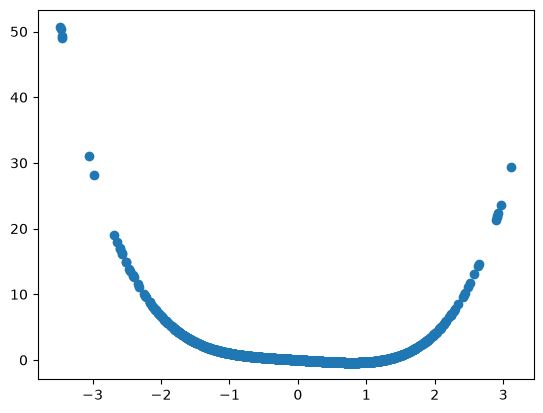

In [142]:
plt.scatter(Train_X,Train_y)

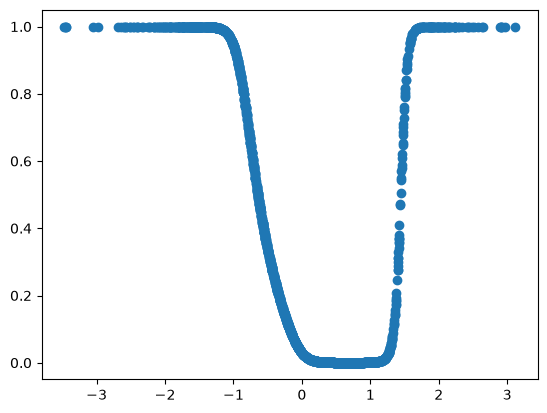

In [143]:
plt.scatter(Train_X,predictions_1)

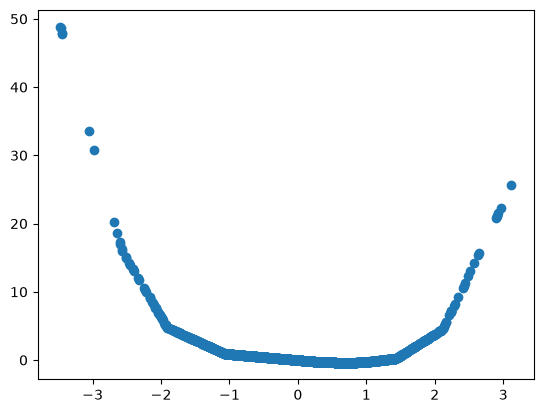

In [144]:
plt.scatter(Train_X,predictions_2)

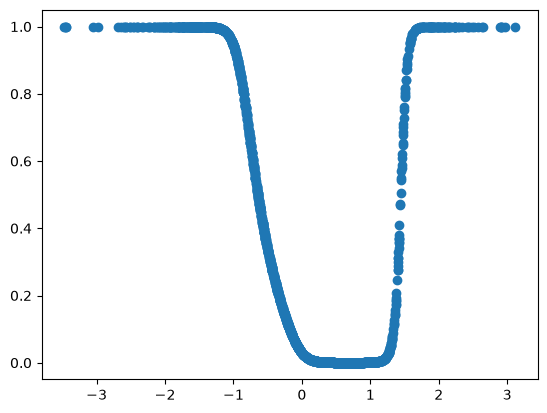

In [145]:
plt.scatter(Train_X,predictions_3)